<a href="https://colab.research.google.com/github/sunyuhongwr/-/blob/main/machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第二讲：用机器学习给睡眠分期

**目标：** 亲手训练出一个能自动判读睡眠分期的随机森林模型，并知道怎样正确地检验它。

**路线：** 脑电信号 → 特征（几个数字）→ 分类器 → 睡眠分期

**notebook使用：**
- 每个灰色方框是一段代码，点一下方框，再按 `Shift + Enter` 就会运行，结果显示在方框下面。
- 请**从上到下按顺序**运行。
- 标有 ✏️ 的地方是可以动手修改尝试的。改完可以再按 `Shift + Enter` 看结果出现了什么变化。

**数据：** 20 位被试各一整晚的睡眠记录（共 20 晚），每 30 秒由专家标注一个睡眠分期（Wake、N1、N2、N3、REM）。

## 第 0 步：准备工作

运行下面这格代码，它会载入需要的工具并下载数据（约 6 MB）。看到"准备完成"就可以继续。

In [1]:
# 导入依赖
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, recall_score, ConfusionMatrixDisplay

# 数据下载
DRIVE_IDS = {
    "sleep_demo_features.csv": "1oTBQco6K-M7_PyA6gJjZUfCDiBuMQ9Rv",
    "sleep_demo_one_night.npz": "155YknzvQmiX2uB0o3SR6QEKacKu2Bxo6",
}
for name, file_id in DRIVE_IDS.items():
    if os.path.exists(name):
        continue
    if file_id:
        import gdown
        gdown.download(id=file_id, output=name, quiet=False)
    else:
        from google.colab import files
        print(f"请上传文件 {name}")
        files.upload()

# 绘图配置
STAGES = ["Wake", "N1", "N2", "N3", "REM"]  # 分期标签顺序
COLORS = {"Wake": "#D0922A", "N1": "#3DB09A", "N2": "#3D7EC9", "N3": "#63408F", "REM": "#BE4F3C"}
HYPNO_Y = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}  # 分期纵轴位置

def plot_hypnogram(ax, epoch, labels, **style):
    """绘制睡眠结构图。"""
    hours = np.asarray(epoch) * 30 / 3600
    ax.step(hours, [HYPNO_Y[int(v)] for v in labels], where="post", **style)
    ax.set_yticks(range(5))
    ax.set_yticklabels(["N3", "N2", "N1", "REM", "Wake"])
    ax.set_xlabel("Time (hours)")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("准备完成")

Downloading...
From: https://drive.google.com/uc?id=1oTBQco6K-M7_PyA6gJjZUfCDiBuMQ9Rv
To: /content/sleep_demo_features.csv
100%|██████████| 2.13M/2.13M [00:00<00:00, 106MB/s]
Downloading...
From: https://drive.google.com/uc?id=155YknzvQmiX2uB0o3SR6QEKacKu2Bxo6
To: /content/sleep_demo_one_night.npz
100%|██████████| 4.40M/4.40M [00:00<00:00, 16.2MB/s]

准备完成


## 第 1 步：认识数据

### 1.1 一整晚的睡眠长什么样

先载入一位被试整晚的脑电（EEG，导联 C4-M1）。数据已经切成一段一段，每段 30 秒的**epoch**。专家给每个 epoch 标了一个睡眠分期。

这一晚共有 791 个 epoch，每个 epoch 有 3000 个数据点（30 秒 × 100 点/秒）
总时长约 6.6 小时


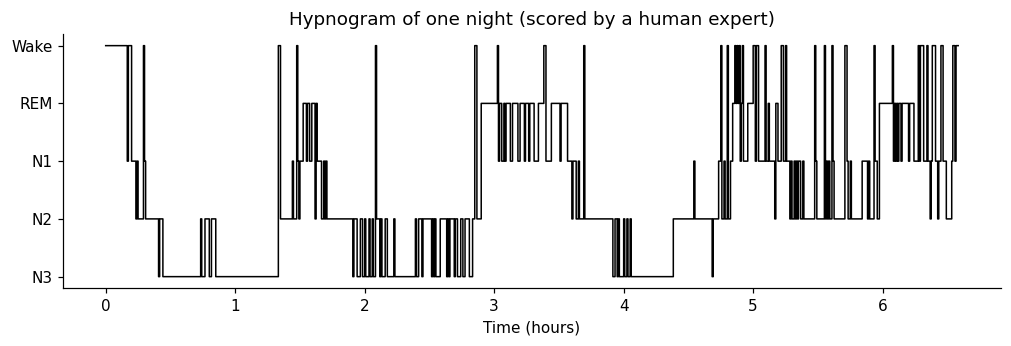

In [2]:
night = np.load("sleep_demo_one_night.npz")
X = night["X"].astype(float)  # EEG：每行 30 秒
y = night["y"]  # 专家分期标签
epoch = night["epoch"]  # 整晚 epoch 索引
fs = int(night["sfreq"])  # 采样率（Hz）

print(f"这一晚共有 {X.shape[0]} 个 epoch，每个 epoch 有 {X.shape[1]} 个数据点（30 秒 × {fs} 点/秒）")
print(f"总时长约 {X.shape[0] * 30 / 3600:.1f} 小时")

fig, ax = plt.subplots(figsize=(11, 3))
plot_hypnogram(ax, epoch, y, color="black", linewidth=1)
ax.set_title("Hypnogram of one night (scored by a human expert)")
plt.show()

这张图叫**睡眠结构图（hypnogram）**。可以看到睡眠不是一个单一的状态，而是在几个分期之间交替：从浅睡（N1、N2）进入深睡（N3），再到快速眼动睡眠（REM），一夜之中重复数次。

### 1.2 各个分期的脑电长什么样

专家就是靠肉眼看下面这样的波形来判断分期的。运行代码，看看你能不能找出各期的差别。

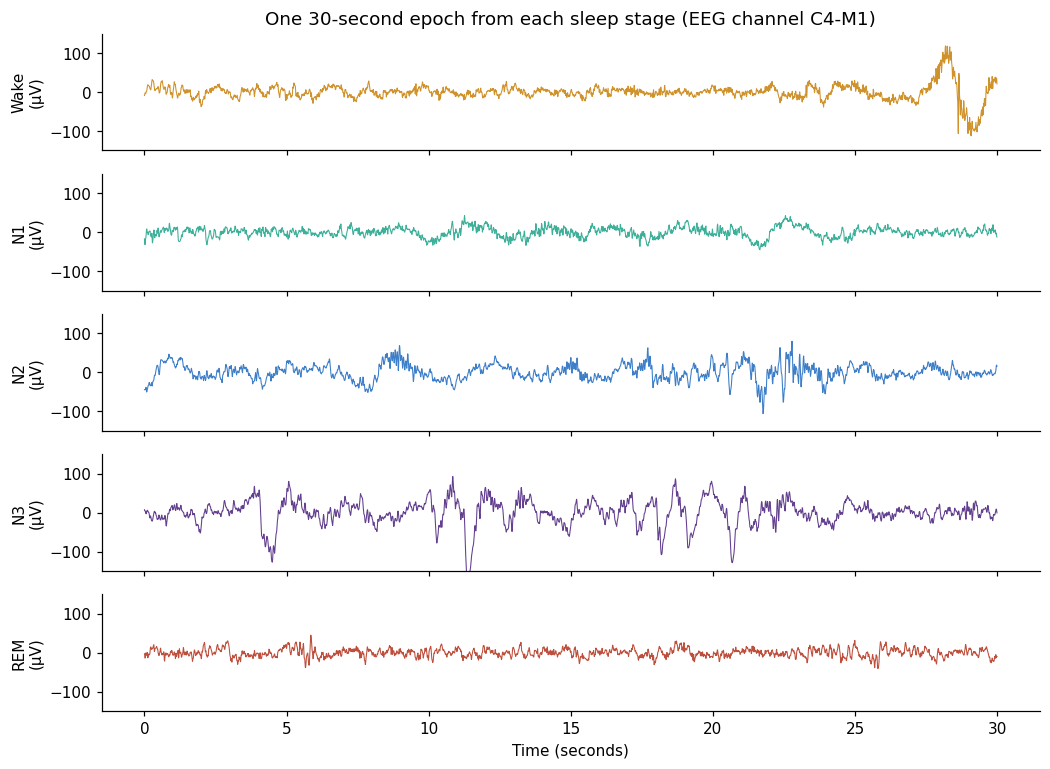

In [3]:
fig, axes = plt.subplots(5, 1, figsize=(11, 8), sharex=True, sharey=True)
t = np.arange(X.shape[1]) / fs
for ax, k in zip(axes, range(5)):
    idx = np.flatnonzero(y == k)
    spread = X[idx].std(axis=1)
    pick = idx[np.argsort(spread)[len(idx) // 2]]  # 选幅度居中的 epoch
    ax.plot(t, X[pick], color=COLORS[STAGES[k]], linewidth=0.7)
    ax.set_ylabel(f"{STAGES[k]}\n(µV)")
axes[0].set_ylim(-150, 150)
axes[0].set_title("One 30-second epoch from each sleep stage (EEG channel C4-M1)")
axes[-1].set_xlabel("Time (seconds)")
plt.show()

**不同睡眠阶段：**
- **N3（深睡）**：又慢又大的波，称为慢波。
- **N2**：偶尔出现一小段快速的"纺锤波"（spindle）。
- **Wake、N1、REM**：幅度小、变化快，三者单看脑电很相似。请记住这一点，后面会用到。

### 1.3 把抽象特征变成具体的数字特征

最常用的办法是**功率谱**：把信号分解成不同频率的成分，看每个频率有多强。

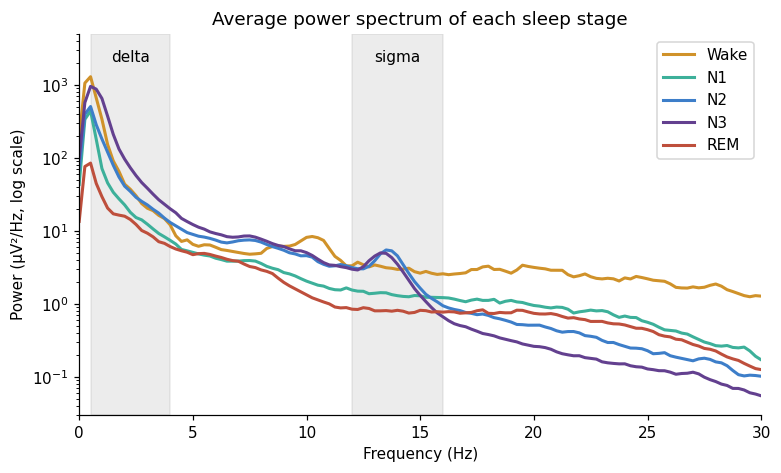

In [4]:
freqs, psd = signal.welch(X, fs=fs, nperseg=4 * fs, axis=-1)  # 逐 epoch 功率谱

fig, ax = plt.subplots(figsize=(8, 4.5))
for k in range(5):
    ax.semilogy(freqs, psd[y == k].mean(axis=0), color=COLORS[STAGES[k]], label=STAGES[k], linewidth=2)
ax.set_xlim(0, 30)
ax.set_ylim(0.03, 5000)
ax.axvspan(0.5, 4, color="grey", alpha=0.15)
ax.axvspan(12, 16, color="grey", alpha=0.15)
ax.text(2.25, 3000, "delta", ha="center", va="top")
ax.text(14, 3000, "sigma", ha="center", va="top")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (µV²/Hz, log scale)")
ax.set_title("Average power spectrum of each sleep stage")
ax.legend()
plt.show()

**观察：**
- **delta 频段（0.5 到 4 Hz）**：在 1 到 4 Hz 之间 N3 的线最高，对应刚才看到的慢波。
- **sigma 频段（12 到 16 Hz）**：N2 和 N3 有一个小鼓包，对应纺锤波。
- **15 Hz 以上的高频**：清醒时最强，睡得越深越弱。

所以"delta 频段的功率占多少"就是一个能区分睡眠分期的数字，可以被称为**特征（feature）**。

## 第 2 步：特征表

我们已经提前为 20 晚的每一个 epoch 算好了 13 个特征，存成了一张表。**每一行是一个 epoch，每一列是一个特征。**

In [5]:
df = pd.read_csv("sleep_demo_features.csv")
print(f"共 {len(df)} 个 epoch，来自 {df['subject'].nunique()} 位被试")
df.head()

共 16700 个 epoch，来自 20 位被试


,subject,split,epoch,stage,label,eeg_delta_rel,eeg_theta_rel,eeg_alpha_rel,eeg_sigma_rel,eeg_beta_rel,eeg_log_power,eeg_hjorth_mobility,eeg_hjorth_complexity,eog_log_power,eog_log_p2p,eog_log_slope,eog_lr_corr,emg_log_power
0,S01,train,0,Wake,0,0.39002,0.048796,0.106190,0.080908,0.37409,1.9628,0.91578,1.5161,1.22620,0.48641,0.37106,-0.93118,0.22944
1,S01,train,1,Wake,0,0.49705,0.071014,0.079722,0.069116,0.28309,1.8694,0.80207,1.7135,1.19990,0.52925,0.41691,-0.88713,1.00390
2,S01,train,2,Wake,0,0.40963,0.063473,0.086472,0.098300,0.34213,1.8105,0.89397,1.5591,0.81448,0.28653,0.24084,-0.88994,0.24988
3,S01,train,3,Wake,0,0.48299,0.101060,0.101180,0.076605,0.23817,1.8198,0.75412,1.7957,1.15580,0.44783,0.32152,-0.93289,0.19543
4,S01,train,4,Wake,0,0.54607,0.106860,0.118300,0.048040,0.18073,1.8430,0.66346,2.0043,1.33240,0.44805,0.20079,-0.91965,0.16353


各列的含义：

| 列名 | 含义 |
|---|---|
| `subject` | 被试编号（S01 到 S20，每人一晚） |
| `split` | `train` = 训练集 13 人，`val` = 验证集 3 人，`test` = 测试集 4 人 |
| `stage`、`label` | 专家标注的分期（文字和数字两种写法） |
| `eeg_delta_rel` 等 5 列 | 脑电各频段的功率占比：delta、theta、alpha、sigma、beta |
| `eeg_log_power` | 脑电总能量（幅度大小） |
| `eeg_hjorth_mobility`、`eeg_hjorth_complexity` | 脑电波形变化的快慢和复杂程度 |
| `eog_...` 4 列 | 眼电（EOG）：眼球运动的大小、快慢，以及左右眼是否反向 |
| `emg_log_power` | 下颌肌电（EMG）：肌肉的紧张程度 |

**三个集合各有分工，而且是按人划分的：**
- **训练集**：模型从这里学习。
- **验证集**：用它来挑选不同的模型或设置。
- **测试集**：回答挑选后的模型真实能力如何。

看看其中两个特征在各分期的取值分布：

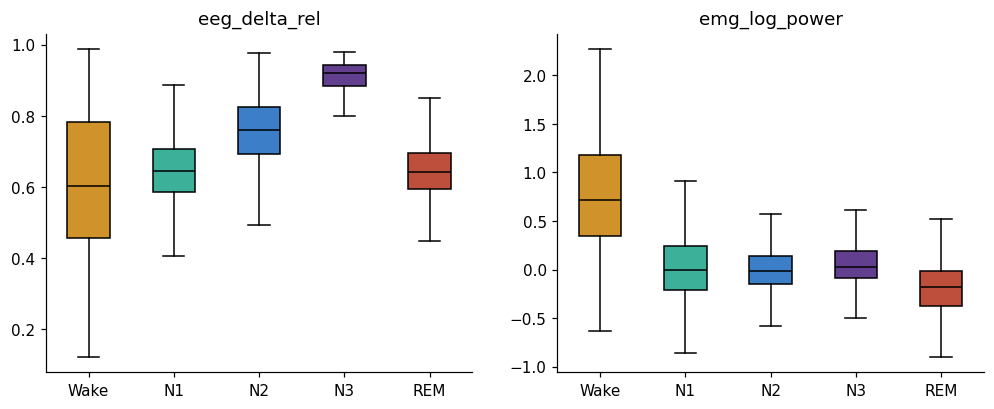

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ["eeg_delta_rel", "emg_log_power"]):  # ✏️ 待绘制特征
    data = [df.loc[df["stage"] == s, feature] for s in STAGES]
    box = ax.boxplot(data, showfliers=False, patch_artist=True, medianprops={"color": "black"})
    ax.set_xticks(range(1, 6))
    ax.set_xticklabels(STAGES)
    for patch, s in zip(box["boxes"], STAGES):
        patch.set_facecolor(COLORS[s])
    ax.set_title(feature)
plt.show()

**观察：** delta 占比能把 N3 分出来；肌电在清醒时最高、REM 时最低。单个特征只能区分一部分分期，所以需要把多个特征**组合**起来，这正是机器学习擅长的事。

## 第 3 步：训练你的第一个模型

机器学习的流程只有三步：

1. **准备数据**：按被试划分成训练集、验证集和测试集。
2. **训练（fit）**：把训练集的特征和专家的答案交给模型，让它自己找规律。
3. **预测（predict）**：让模型给测试集的 4 个人分期，再和专家的答案对比。

我们先只用 8 个脑电特征，模型用**随机森林（random forest）**，参数用默认设置。

In [7]:
eeg_features = ["eeg_delta_rel", "eeg_theta_rel", "eeg_alpha_rel", "eeg_sigma_rel", "eeg_beta_rel",
                "eeg_log_power", "eeg_hjorth_mobility", "eeg_hjorth_complexity"]
eog_emg_features = ["eog_log_power", "eog_log_p2p", "eog_log_slope", "eog_lr_corr", "emg_log_power"]

# 划分数据集
train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
test = df[df["split"] == "test"]
for name, part in (("训练集", train), ("验证集", val), ("测试集", test)):
    print(f"{name}：{part['subject'].nunique()} 人，{len(part)} 个 epoch")

# 训练模型
features = eeg_features
model = RandomForestClassifier(n_estimators=100, random_state=0)
model.fit(train[features], train["label"])

# 预测分期
pred = model.predict(test[features])
print("\n训练完成。模型对测试集前 20 个 epoch 的判断：", [STAGES[k] for k in pred[:20]])

训练集：13 人，10653 个 epoch
验证集：3 人，2589 个 epoch
测试集：4 人，3458 个 epoch

训练完成。模型对测试集前 20 个 epoch 的判断： ['Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake', 'Wake']


## 第 4 步：模型表现

### 4.1 总体成绩

- **准确率（accuracy）**：模型和专家判断一致的 epoch 占多少。
- **宏 F1（macro-F1）**：先给每个分期单独打分，再取平均，每个分期同等重要。N2 的 epoch 最多，只看准确率容易忽略 N1 这样的"小"分期。
- **Cohen's kappa**：扣除"蒙对"的成分之后的一致程度，0 表示和瞎猜一样，1 表示完全一致。

In [8]:
print(f"准确率: {accuracy_score(test['label'], pred):.1%}")
print(f"宏 F1 : {f1_score(test['label'], pred, average='macro'):.2f}")
print(f"kappa : {cohen_kappa_score(test['label'], pred):.2f}")

准确率: 77.2%
宏 F1 : 0.71
kappa : 0.69


### 4.2 哪些分期容易搞错：混淆矩阵

每一行是专家标注的分期，每一列是模型的判断。对角线上的数字越接近 1 越好。

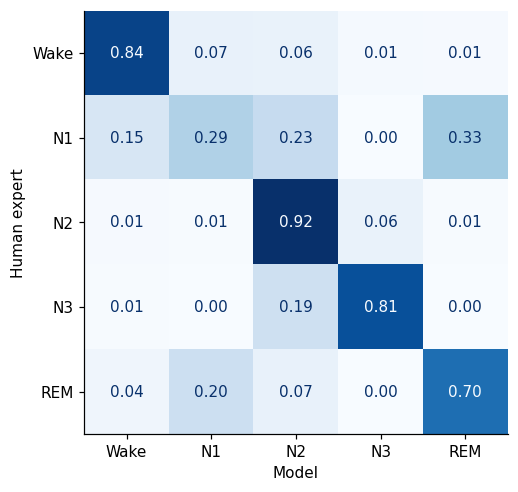

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(test["label"], pred, display_labels=STAGES, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Model")
ax.set_ylabel("Human expert")
plt.show()



### 4.3 把模型的判断画成睡眠结构图

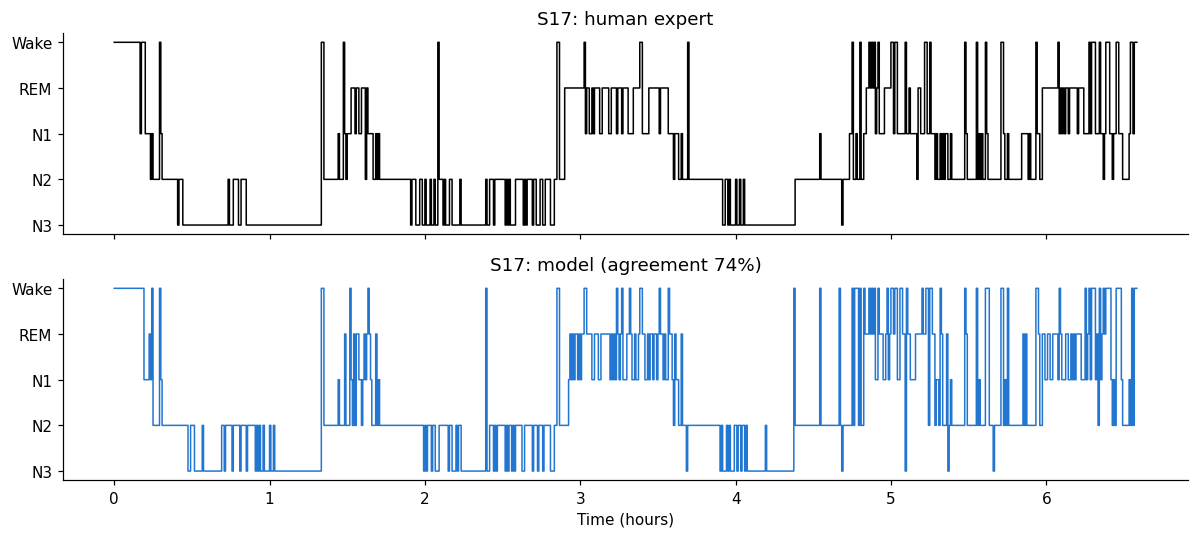

In [10]:
subject = "S17"  # ✏️ 绘图被试
rows = (test["subject"] == subject).to_numpy()
one = test[rows].sort_values("epoch")
one_pred = pd.Series(pred[rows], index=test[rows].index).loc[one.index]

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
plot_hypnogram(axes[0], one["epoch"], one["label"], color="black", linewidth=1)
axes[0].set_title(f"{subject}: human expert")
axes[0].set_xlabel("")
plot_hypnogram(axes[1], one["epoch"], one_pred, color="#2376CF", linewidth=1)
axes[1].set_title(f"{subject}: model (agreement {accuracy_score(one['label'], one_pred):.0%})")
plt.tight_layout()
plt.show()

模型抓住了整晚睡眠的大致结构，但比专家的结果"毛躁"，因为它每次只看一个 epoch，不知道前后发生了什么。

## 第 5 步：✏️ 动手改一改

下面这格代码把"训练 + 评估"打包成了一个函数 `run_experiment`，之后每做一次实验只需要一行。先运行它。

注意参数 `evaluate_on`：
- `"val"`（默认）：在**验证集**上评估。尝试不同的模型或特征属于"挑选"，应该用验证集。
- `"test"`：在**测试集**上评估。只用于事先定好的最终比较。

In [11]:
results = {}  # 实验指标

def run_experiment(name, features, model=None, evaluate_on="val"):
    """训练模型并记录指定数据集的指标。"""
    if model is None:
        model = RandomForestClassifier(n_estimators=100, random_state=0)
    data = val if evaluate_on == "val" else test
    model.fit(train[features], train["label"])
    pred = model.predict(data[features])
    acc = accuracy_score(data["label"], pred)
    f1 = f1_score(data["label"], pred, average="macro")
    recall = recall_score(data["label"], pred, labels=range(len(STAGES)), average=None, zero_division=0)
    results[f"{name} [{evaluate_on}]"] = [acc, f1] + list(recall)
    print(f"{name}（{'验证集' if evaluate_on == 'val' else '测试集'}）：准确率 {acc:.1%}，宏 F1 {f1:.2f}")
    print("各分期判对的比例：" + "，".join(f"{s} {r:.0%}" for s, r in zip(STAGES, recall)))
    return model

model = run_experiment("EEG only", eeg_features, evaluate_on="test")

EEG only（测试集）：准确率 77.2%，宏 F1 0.71
各分期判对的比例：Wake 84%，N1 29%，N2 92%，N3 81%，REM 70%


### 练习 1（选做）：给模型更多信息

专家判读时除了脑电，还会看**眼电（EOG）**和**肌电（EMG）**：REM 期眼球快速转动，同时全身肌肉放松。把这些特征也交给模型，看看 REM 和其他分期的识别有没有变化。

这是一个事先定好的比较（只用脑电，对比加入眼电和肌电），所以直接在测试集上看结果。

In [12]:
model = run_experiment("EEG + EOG + EMG", eeg_features + eog_emg_features, evaluate_on="test")

EEG + EOG + EMG（测试集）：准确率 80.6%，宏 F1 0.77
各分期判对的比例：Wake 82%，N1 51%，N2 94%，N3 84%，REM 65%


和上面"EEG only"的结果比一比：哪个分期变化最大？REM 改善了吗？

### 练习 2（选做）：换一个模型

所有模型使用同样的 8 个 EEG 特征、同一批训练被试，并在同一批验证被试上评估。随机森林（100 棵树）是第 3 步模型的参照。

| 选项 | 它怎么分期 | 可以改什么 |
|---|---|---|
| Random forest (100 trees / 10 trees) | 多棵树投票，比较树的数量有何影响 | `n_estimators` |
| Logistic regression | 用特征的线性组合给各期打分 | `C` |
| KNN | 找最相似的 epoch，让邻居投票 | `n_neighbors` |
| RBF SVM | 用 RBF 核学习非线性分类边界 | `C` 或 `gamma` |
| Decision tree | 按特征阈值逐步把样本分开 | `max_depth` |
| Gradient boosting | 逐步加树，改进上一轮的预测 | `max_iter` 或 `learning_rate` |

先运行默认设置，再试着一次只改一个参数。想把原版与修改版放在一起比较，可以取消代码里的 SVM 变体注释。逻辑回归、KNN 和 SVM 都用 `StandardScaler`，缩放参数仅从训练集学习。

In [13]:
models = {
    "Random forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=0),
    "Random forest (10 trees)": RandomForestClassifier(n_estimators=10, random_state=0),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "RBF SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
    "Decision tree": DecisionTreeClassifier(max_depth=6, random_state=0),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=100, early_stopping=False, random_state=0),
}

# ✏️ SVM 对照配置：C=10
# models["RBF SVM (C=10)"] = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))

selected_models = list(models)  # ✏️ 待比较模型
for name in selected_models:
    run_experiment(name, eeg_features, model=models[name], evaluate_on="val")

Random forest (100 trees)（验证集）：准确率 77.4%，宏 F1 0.70
各分期判对的比例：Wake 81%，N1 18%，N2 93%，N3 79%，REM 87%
Random forest (10 trees)（验证集）：准确率 75.4%，宏 F1 0.68
各分期判对的比例：Wake 78%，N1 21%，N2 92%，N3 75%，REM 80%
Logistic regression（验证集）：准确率 76.0%，宏 F1 0.65
各分期判对的比例：Wake 68%，N1 8%，N2 93%，N3 78%，REM 94%
KNN（验证集）：准确率 75.5%，宏 F1 0.67
各分期判对的比例：Wake 72%，N1 15%，N2 90%，N3 78%，REM 90%
RBF SVM（验证集）：准确率 77.7%，宏 F1 0.67
各分期判对的比例：Wake 79%，N1 8%，N2 94%，N3 81%，REM 92%
Decision tree（验证集）：准确率 72.0%，宏 F1 0.64
各分期判对的比例：Wake 66%，N1 18%，N2 88%，N3 76%，REM 75%
Gradient boosting（验证集）：准确率 77.6%，宏 F1 0.71
各分期判对的比例：Wake 81%，N1 21%，N2 91%，N3 79%，REM 90%


#### 模型对比（同一验证集）

表格和左图对比准确率与宏 F1。右图显示各期的**召回率**，即专家标注为该期的 epoch 中，有多少被模型判对。

试着找出整体成绩接近、但 N1 或 REM 召回率不同的两个模型。改一个参数后，重跑上面的训练格和下面的绘图格，看看哪一期受影响最大。

,Accuracy,Macro-F1,Wake,N1,N2,N3,REM
Gradient boosting,77.6%,70.8%,80.7%,21.1%,91.0%,78.8%,89.5%
Random forest (100 trees),77.4%,69.6%,80.7%,17.5%,92.5%,78.8%,86.8%
Random forest (10 trees),75.4%,68.3%,77.6%,21.3%,92.0%,74.5%,79.6%
RBF SVM,77.7%,67.5%,78.8%,8.2%,94.0%,80.6%,92.0%
KNN,75.5%,67.3%,71.8%,14.9%,90.1%,77.8%,90.4%
Logistic regression,76.0%,65.2%,67.6%,7.6%,93.4%,78.0%,94.2%
Decision tree,72.0%,64.1%,66.4%,18.1%,88.2%,75.7%,75.2%


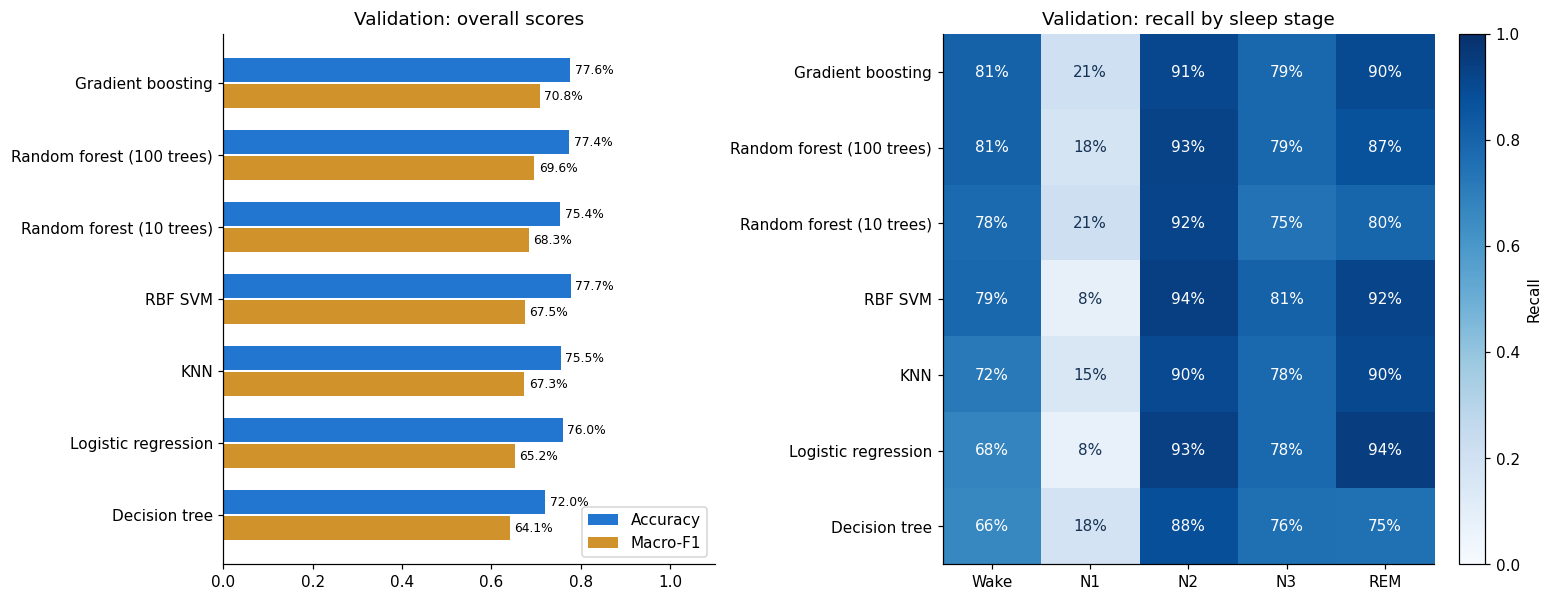

In [14]:
model_table = pd.DataFrame(
    {name: results[f"{name} [val]"] for name in selected_models},
    index=["Accuracy", "Macro-F1"] + STAGES,
).T.sort_values("Macro-F1", ascending=False)
display(model_table.style.format("{:.1%}"))

fig, (ax_scores, ax_recall) = plt.subplots(
    1, 2, figsize=(14, max(4, 0.55 * len(model_table) + 1.5)), layout="constrained"
)
positions = np.arange(len(model_table))
for metric, offset, color in [("Accuracy", -0.18, "#2376CF"), ("Macro-F1", 0.18, "#D0922A")]:
    bars = ax_scores.barh(positions + offset, model_table[metric], height=0.34, label=metric, color=color)
    ax_scores.bar_label(bars, fmt="{:.1%}", padding=3, fontsize=8)
ax_scores.set_yticks(positions, model_table.index)
ax_scores.invert_yaxis()
ax_scores.set_xlim(0, 1.1)
ax_scores.set_xticks(np.linspace(0, 1, 6))
ax_scores.set_title("Validation: overall scores")
ax_scores.legend(loc="lower right")

recall_values = model_table[STAGES].to_numpy()
heatmap = ax_recall.imshow(recall_values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax_recall.set_xticks(range(len(STAGES)), STAGES)
ax_recall.set_yticks(positions, model_table.index)
ax_recall.set_title("Validation: recall by sleep stage")
for row, recalls in enumerate(recall_values):
    for col, value in enumerate(recalls):
        ax_recall.text(col, row, f"{value:.0%}", ha="center", va="center",
                       color="white" if value >= 0.6 else "#163354")
fig.colorbar(heatmap, ax=ax_recall, label="Recall")
plt.show()

### 练习 3（选做）：模型最看重哪些特征

随机森林可以告诉我们每个特征的重要程度。

In [ ]:
forest = RandomForestClassifier(n_estimators=100, random_state=0).fit(train[eeg_features], train["label"])
order = np.argsort(forest.feature_importances_)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([eeg_features[i] for i in order], forest.feature_importances_[order], color="#2376CF")
ax.set_xlabel("Importance")
ax.set_title("Which EEG features does the random forest rely on?")
plt.show()

✏️ **试一试：** 从特征里去掉最重要的那一个，验证集成绩会掉多少？也可以把 `remove` 换成别的特征名再运行。

如果成绩几乎没变，想一想为什么。

In [ ]:
remove = "eeg_beta_rel"  # ✏️ 移除的特征
fewer = [f for f in eeg_features if f != remove]
_ = run_experiment(f"without {remove}", fewer)

把所有实验的成绩放在一起比较（方括号里标明了是在验证集还是测试集上评估的，两者不能直接相比）：

In [ ]:
table = pd.DataFrame(results, index=["accuracy", "macro-F1"] + STAGES).T.round(2)
table

## 第 6 步：跨被试迁移注意事项

到目前为止，我们一直**按人**划分数据：测试集的 4 个人，训练时一个 epoch 都没出现过。如果偷个懒，把训练集和测试集所有人的 epoch 混在一起，再随机抽出同样数量的 epoch 来测试，会怎么样？

In [ ]:
pool = pd.concat([train, test])  # 合并训练集和测试集

# 按 epoch 随机划分（被试重叠）
X_a, X_b, y_a, y_b = train_test_split(pool[eeg_features], pool["label"], test_size=len(test), random_state=0)
leaky = RandomForestClassifier(n_estimators=100, random_state=0).fit(X_a, y_a)
acc_random = accuracy_score(y_b, leaky.predict(X_b))

# 按被试划分
proper = RandomForestClassifier(n_estimators=100, random_state=0).fit(train[eeg_features], train["label"])
acc_subject = accuracy_score(test["label"], proper.predict(test[eeg_features]))

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["Random epochs\n(same people in\ntrain and test)", "New people\n(participant-level split)"],
              [acc_random, acc_subject], color=["#BE4F3C", "#2376CF"], width=0.55)
ax.bar_label(bars, fmt="{:.1%}")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
plt.show()

**为什么随机划分的成绩更高？** 同一个人相邻的 epoch 非常相似。随机划分时，模型在训练中已经"见过"测试集里每个人的数据，相当于考试前看过了题目。这叫**数据泄漏（data leakage）**。

我们真正关心的问题是："来了一个**新的人**，模型能不能给他分期？"所以必须**按被试划分**：测试集里的人，训练时一个 epoch 都不能出现。如果同一位被试有多晚记录，这些记录也必须放在同一个集合里。

## 小结

一个完整的机器学习项目：

1. **看数据**：不同睡眠分期的脑电在频率和幅度上不一样。
2. **提特征**：用几个有意义的数字（频段功率等）描述每个 epoch。
3. **训练和预测**：`fit` 和 `predict` 两行代码。
4. **评估**：准确率、宏 F1、混淆矩阵，并且要在**没见过的人**身上测试；挑选模型用验证集。
